# Predictive Analytics for Financial Transaction Fraud Detection

Criselvi Lindsey · DSC 680 Project 1

## Project overview

This notebook evaluates fraud-detection classifiers on the synthetic BankSim dataset (Lopez-Rojas & Axelsson, 2014). The central question is how classification methods balance detection of rare fraudulent transactions (1.21% of records) against false alerts that create investigative workload.

Structure of the notebook

1. Data loading, quality checks, and exploratory analysis
2. Feature selection and a stratified 80/20 holdout split
3. Four models — logistic regression, class-weighted logistic regression, random forest, and histogram-based gradient boosting — each with the rationale for including it
4. Expanded validation: 5-fold stratified cross-validation of all four models, hyperparameter tuning of logistic regression and gradient boosting, and decision-threshold selection from out-of-fold training predictions
5. Sensitivity tests: merchant/step feature ablation, a time-based (train-on-earlier-steps) validation, and an encoding comparison
6. Fairness and ethics: age and gender subgroup performance with 95% confidence intervals and significance tests, plus a risk register with specific likelihood and impact ratings
7. Summary of findings

All results describe synthetic BankSim data and are not estimates of production performance at a real institution.

In [28]:
'''
Submitted by: Criselvi Lindsey
Class: DSC680 Project 1 (Revised)
Revision date: 10/15/2026
'''

'\nSubmitted by: Criselvi Lindsey\nClass: DSC680 Project 1 (Revised)\nRevision date: 10/15/2026\n'

## Environment and reproducibility

Import the analysis, plotting, and scikit-learn tools used below and print the library versions. The notebook expects bs140513_032310.csv (BankSim, Kaggle) in the working directory. All random states use seed 42.

Exact scores for tree-based models can shift slightly between scikit-learn versions; the saved outputs in this notebook were produced with the versions printed by the cell below.

In [29]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.inspection import permutation_importance

import platform
import warnings
import numpy as np
import matplotlib
import sklearn
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

print("Python      ", platform.python_version())
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)

Python       3.12.4
pandas       2.2.3
numpy        2.1.3
scikit-learn 1.8.0
matplotlib   3.10.8


## Load and inspect the dataset

Load the BankSim transaction file and inspect its shape, column types, missingness, and duplicates. Because the dataset is synthetic, findings cannot automatically be generalized to operational banking data.


In [30]:
# Load the BankSim dataset
df = pd.read_csv("bs140513_032310.csv")

# Basic dataset information
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Shape: (594643, 10)

Columns:
['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud']

First 5 rows:
   step       customer  age gender zipcodeOri       merchant zipMerchant             category  amount  fraud
0     0  'C1093826151'  '4'    'M'    '28007'   'M348934600'     '28007'  'es_transportation'    4.55      0
1     0   'C352968107'  '2'    'M'    '28007'   'M348934600'     '28007'  'es_transportation'   39.68      0
2     0  'C2054744914'  '4'    'F'    '28007'  'M1823072687'     '28007'  'es_transportation'   26.89      0
3     0  'C1760612790'  '3'    'M'    '28007'   'M348934600'     '28007'  'es_transportation'   17.25      0
4     0   'C757503768'  '5'    'M'    '28007'   'M348934600'     '28007'  'es_transportation'   35.72      0

Data types:
step             int64
customer        object
age             object
gender          object
zipcodeOri      object
merchant        object
zipMerchant     object
category        o

Findings. The file has 594,643 transactions and 10 columns, with no missing values and no duplicate rows, so no imputation or de-duplication is needed. Categorical fields are stored as quoted strings (e.g., 'M'), which the encoders handle as ordinary category labels.

## Class balance and exploratory data analysis

Examine the fraud target distribution before modeling. Fraud is rare (approximately 1.21% of the records), so raw accuracy can obscure missed fraud. The subsequent summaries inspect transaction amount, merchant category, age, merchant, and simulation step.


In [31]:
# Fraud class distribution
fraud_counts = df["fraud"].value_counts()

print("Fraud counts:")
print(fraud_counts)

print("\nFraud percentages:")
print(df["fraud"].value_counts(normalize=True) * 100)


Fraud counts:
fraud
0    587443
1      7200
Name: count, dtype: int64

Fraud percentages:
fraud
0    98.789189
1     1.210811
Name: proportion, dtype: float64


Findings. Only 7,200 of 594,643 transactions (1.21%) are fraud. A model that labels every transaction legitimate would score 98.79% accuracy while catching no fraud, so accuracy is not used to compare models. The analysis relies on precision, recall, F1, and PR-AUC instead, and the train/test split is stratified.

In [32]:
# Number of unique values in each column
print(df.nunique())


step             180
customer        4112
age                8
gender             4
zipcodeOri         1
merchant          50
zipMerchant        1
category          15
amount         23767
fraud              2
dtype: int64


Findings. zipcodeOri and zipMerchant each have a single value, so they carry no information and are dropped. customer has 4,112 identifiers; including it would let models memorize individual simulated customers rather than learn transferable patterns, so it is excluded. merchant (50 values) and category (15) are manageable categorical predictors.

### Transaction amount by fraud status

Compare the amount distribution overall and by class; large differences suggest amount will be a strong predictor.

In [33]:
print(df["amount"].describe())


count    594643.000000
mean         37.890135
std         111.402831
min           0.000000
25%          13.740000
50%          26.900000
75%          42.540000
max        8329.960000
Name: amount, dtype: float64


In [34]:
print(
    df.groupby("fraud")["amount"]
      .agg(["count", "mean", "median", "min", "max", "std"])
)


        count        mean   median   min      max         std
fraud                                                        
0      587443   31.847230   26.610  0.00  2144.86   31.470876
1        7200  530.926551  319.175  0.03  8329.96  835.587112


Findings. Fraudulent transactions are far larger: median \$319.18 versus \$26.61 for legitimate ones, and the fraud maximum (\$8,329.96) is nearly four times the legitimate maximum (\$2,144.86). Amount is therefore expected to be a strong predictor.

### Fraud by transaction category

Compute both the fraud rate and fraud count per category, since a high-rate category can still contain few cases.

In [35]:
category_analysis = (
    df.groupby("category")["fraud"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

category_analysis.columns = [
    "category",
    "total_transactions",
    "fraudulent_transactions",
    "fraud_rate"
]

category_analysis["fraud_rate_percent"] = (
    category_analysis["fraud_rate"] * 100
)

category_analysis = category_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
)

print(category_analysis.to_string(index=False))


               category  total_transactions  fraudulent_transactions  fraud_rate  fraud_rate_percent
           'es_leisure'                 499                      474    0.949900           94.989980
            'es_travel'                 728                      578    0.793956           79.395604
     'es_sportsandtoys'                4002                     1982    0.495252           49.525237
     'es_hotelservices'                1744                      548    0.314220           31.422018
     'es_otherservices'                 912                      228    0.250000           25.000000
              'es_home'                1986                      302    0.152064           15.206445
            'es_health'               16133                     1696    0.105126           10.512614
              'es_tech'                2370                      158    0.066667            6.666667
 'es_wellnessandbeauty'               15086                      718    0.047594           

Findings. Fraud is concentrated in a few categories. Leisure (95.0%), travel (79.4%) and sports & toys (49.5%) have the highest rates, while transportation, food and contents (more than 532,000 transactions combined) contain no fraud at all. Sports & toys has the most cases (1,982), showing that fraud rate and fraud volume rank categories differently.

### Fraud by coded age group and gender

These descriptive rates are also the starting point for the subgroup fairness analysis later in the notebook.

In [36]:
# Fraud analysis by age
age_analysis = (
    df.groupby("age")["fraud"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

age_analysis.columns = [
    "age",
    "total_transactions",
    "fraudulent_transactions",
    "fraud_rate"
]

age_analysis["fraud_rate_percent"] = age_analysis["fraud_rate"] * 100

print("Fraud by age:")
print(age_analysis.to_string(index=False))


# Fraud analysis by gender
gender_analysis = (
    df.groupby("gender")["fraud"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

gender_analysis.columns = [
    "gender",
    "total_transactions",
    "fraudulent_transactions",
    "fraud_rate"
]

gender_analysis["fraud_rate_percent"] = gender_analysis["fraud_rate"] * 100

print("\nFraud by gender:")
print(gender_analysis.to_string(index=False))


Fraud by age:
age  total_transactions  fraudulent_transactions  fraud_rate  fraud_rate_percent
'0'                2452                       48    0.019576            1.957586
'1'               58131                      689    0.011853            1.185254
'2'              187310                     2344    0.012514            1.251401
'3'              147131                     1755    0.011928            1.192815
'4'              109025                     1410    0.012933            1.293281
'5'               62642                      686    0.010951            1.095112
'6'               26774                      261    0.009748            0.974826
'U'                1178                        7    0.005942            0.594228

Fraud by gender:
gender  total_transactions  fraudulent_transactions  fraud_rate  fraud_rate_percent
   'E'                1178                        7    0.005942            0.594228
   'F'              324565                     4758    0.014660        

Findings. Fraud rates differ only modestly across coded age groups (0.97%–1.96%, excluding the 1,178 'U' records) and gender (1.47% F vs. 0.91% M). Because these attributes could become a fairness concern if a model performed unevenly across them, subgroup performance is evaluated explicitly later in the notebook.

### Fraud by merchant

Rank merchants by fraud count and by fraud rate to see how concentrated fraud is.

In [37]:
merchant_analysis = (
    df.groupby("merchant")["fraud"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

merchant_analysis.columns = [
    "merchant",
    "total_transactions",
    "fraudulent_transactions",
    "fraud_rate"
]

merchant_analysis["fraud_rate_percent"] = (
    merchant_analysis["fraud_rate"] * 100
)

# Merchants with the most fraud cases
merchant_by_count = merchant_analysis.sort_values(
    "fraudulent_transactions",
    ascending=False
)

print("Top 10 merchants by number of fraudulent transactions:")
print(merchant_by_count.head(10).to_string(index=False))

# Merchants with the highest fraud rates
merchant_by_rate = merchant_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
)

print("\nTop 10 merchants by fraud rate:")
print(merchant_by_rate.head(10).to_string(index=False))


Top 10 merchants by number of fraudulent transactions:
     merchant  total_transactions  fraudulent_transactions  fraud_rate  fraud_rate_percent
 'M480139044'                3508                     1634    0.465792           46.579247
 'M980657600'                1769                     1472    0.832109           83.210854
 'M732195782'                 608                      518    0.851974           85.197368
'M1198415165'                1580                      358    0.226582           22.658228
   'M3697346'                 308                      290    0.941558           94.155844
 'M855959430'                6098                      280    0.045917            4.591669
'M1888755466'                 912                      228    0.250000           25.000000
'M1873032707'                 250                      216    0.864000           86.400000
'M2122776122'                 341                      200    0.586510           58.651026
'M1741626453'                 528  

Findings. Fraud is highly concentrated among the 50 merchants. M480139044 alone accounts for 1,634 fraud cases (23% of all fraud), and several merchants have fraud rates above 80%. Such extreme merchant-level patterns may reflect how BankSim generated fraud rather than real merchant behaviour, which motivates the merchant-ablation test.

### Fraud by simulation step

Check whether the fraud count varies over the simulated time steps.

In [38]:
step_analysis = (
    df.groupby("step")["fraud"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

step_analysis.columns = [
    "step",
    "total_transactions",
    "fraudulent_transactions",
    "fraud_rate"
]

step_analysis["fraud_rate_percent"] = (
    step_analysis["fraud_rate"] * 100
)

print(step_analysis.head(10).to_string(index=False))

print("\nLast 10 steps:")
print(step_analysis.tail(10).to_string(index=False))

print("\nFraud rate summary across steps:")
print(step_analysis["fraud_rate_percent"].describe())


 step  total_transactions  fraudulent_transactions  fraud_rate  fraud_rate_percent
    0                2430                       40    0.016461            1.646091
    1                2424                       40    0.016502            1.650165
    2                2462                       40    0.016247            1.624695
    3                2499                       40    0.016006            1.600640
    4                2532                       40    0.015798            1.579779
    5                2525                       40    0.015842            1.584158
    6                2580                       40    0.015504            1.550388
    7                2539                       40    0.015754            1.575423
    8                2575                       40    0.015534            1.553398
    9                2638                       40    0.015163            1.516300

Last 10 steps:
 step  total_transactions  fraudulent_transactions  fraud_rate  fraud_r

In [39]:
print(
    step_analysis.sort_values(
        "fraud_rate_percent",
        ascending=False
    ).head(10).to_string(index=False)
)


 step  total_transactions  fraudulent_transactions  fraud_rate  fraud_rate_percent
    1                2424                       40    0.016502            1.650165
    0                2430                       40    0.016461            1.646091
    2                2462                       40    0.016247            1.624695
    3                2499                       40    0.016006            1.600640
    5                2525                       40    0.015842            1.584158
    4                2532                       40    0.015798            1.579779
    7                2539                       40    0.015754            1.575423
    8                2575                       40    0.015534            1.553398
    6                2580                       40    0.015504            1.550388
   10                2622                       40    0.015256            1.525553


In [40]:
fraud_per_step = df.groupby("step")["fraud"].sum()
print("Fraud cases per step - min:", fraud_per_step.min(), " max:", fraud_per_step.max(),
      " unique values:", sorted(int(v) for v in fraud_per_step.unique()))
print("Transactions per step - min:", df.groupby("step").size().min(), " max:", df.groupby("step").size().max())

Fraud cases per step - min: 40  max: 40  unique values: [40]
Transactions per step - min: 2424  max: 3774


Findings. Every one of the 180 simulation steps contains exactly 40 fraud cases, while total transactions per step grow from about 2,400 to 3,770. As a result, the per-step fraud rate falls mechanically from about 1.65% to 1.07%. This is a property of the simulator, not of fraud behaviour, so the step feature is tested by ablation and by a time-based validation.

## Exploratory visualizations

Plot class balance, merchant-category fraud rates, and transaction amount distributions to make the imbalance and potential signals visible. Any apparent association is descriptive and does not establish causation or real-world predictive validity.


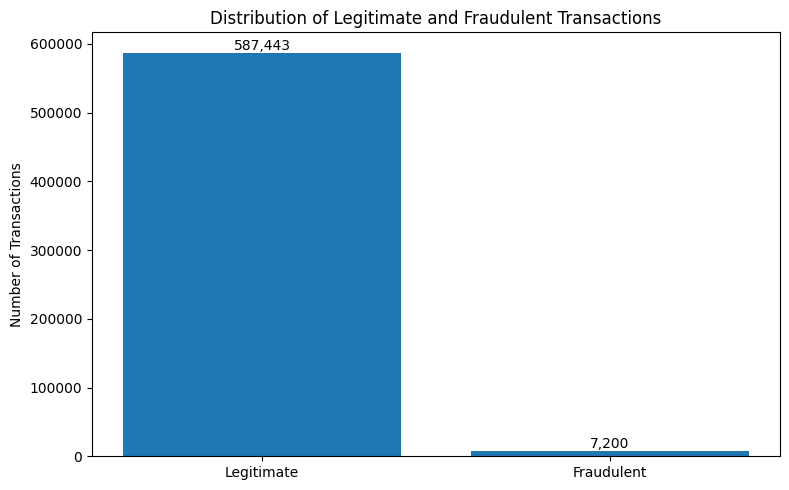

In [41]:
# Count legitimate and fraudulent transactions
fraud_counts = df["fraud"].value_counts().sort_index()

labels = ["Legitimate", "Fraudulent"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, fraud_counts.values)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.ylabel("Number of Transactions")

# Add counts above bars
for bar, count in zip(bars, fraud_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


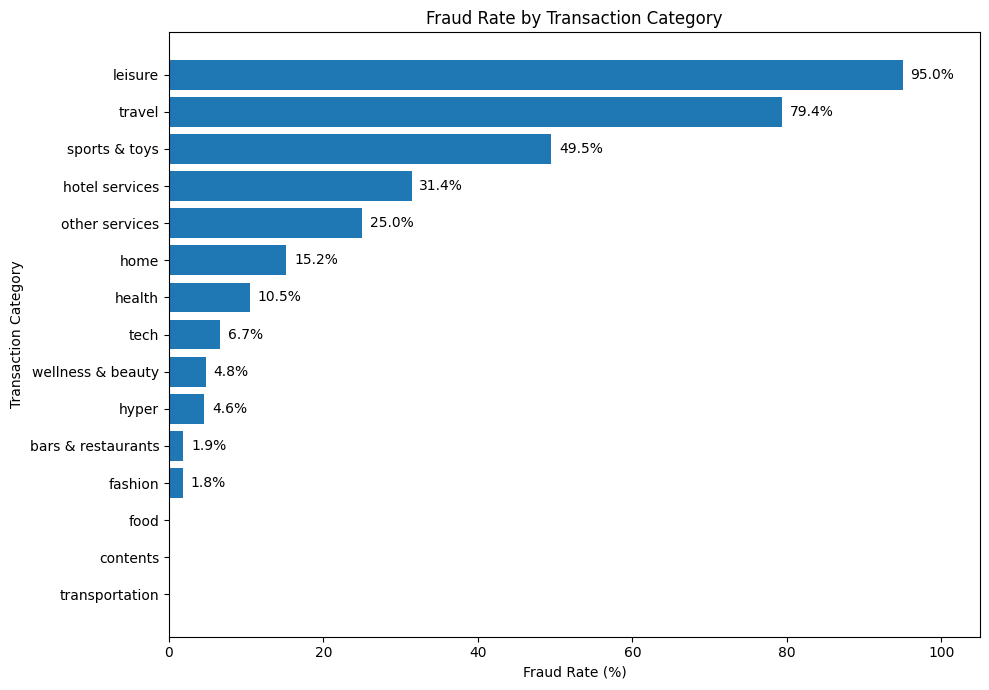

In [42]:
# Make cleaner category names
category_plot = category_analysis.copy()

category_plot["category_clean"] = (
    category_plot["category"]
    .str.replace("'", "", regex=False)
    .str.replace("es_", "", regex=False)
    .str.replace("hotelservices", "hotel services", regex=False)
    .str.replace("otherservices", "other services", regex=False)
    .str.replace("sportsandtoys", "sports & toys", regex=False)
    .str.replace("wellnessandbeauty", "wellness & beauty", regex=False)
    .str.replace("barsandrestaurants", "bars & restaurants", regex=False)
)

category_plot = category_plot.sort_values(
    "fraud_rate_percent",
    ascending=True
)

plt.figure(figsize=(10, 7))

bars = plt.barh(
    category_plot["category_clean"],
    category_plot["fraud_rate_percent"]
)

plt.title("Fraud Rate by Transaction Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Category")

# Add percentage labels
for bar, rate in zip(bars, category_plot["fraud_rate_percent"]):
    if rate > 0:
        plt.text(
            bar.get_width() + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.1f}%",
            va="center"
        )

plt.xlim(0, 105)
plt.tight_layout()
plt.show()


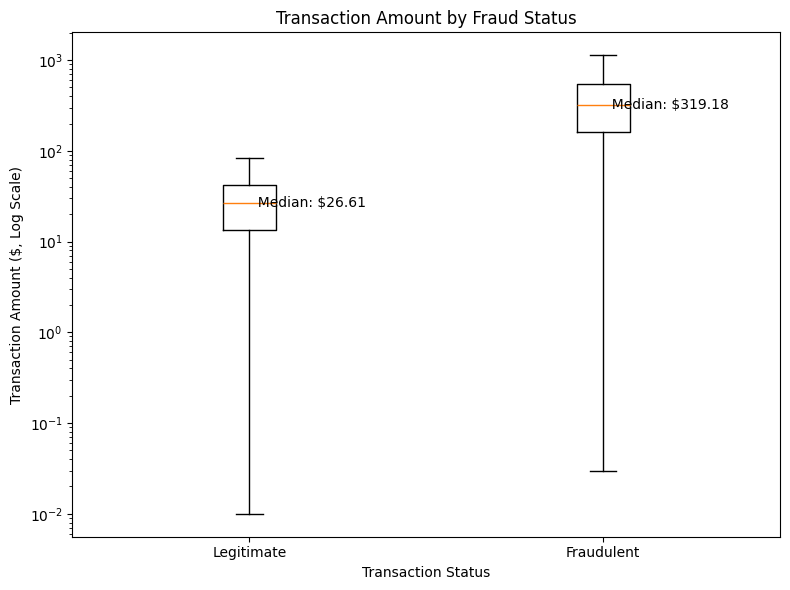

In [43]:
# Exclude zero amounts only for the log-scale visualization
amount_plot = df[df["amount"] > 0].copy()
median_legit = df.loc[df["fraud"] == 0, "amount"].median()
median_fraud = df.loc[df["fraud"] == 1, "amount"].median()

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        amount_plot.loc[amount_plot["fraud"] == 0, "amount"],
        amount_plot.loc[amount_plot["fraud"] == 1, "amount"]
    ],
    tick_labels=["Legitimate", "Fraudulent"],
    showfliers=False
)

plt.yscale("log")

plt.title("Transaction Amount by Fraud Status")
plt.ylabel("Transaction Amount ($, Log Scale)")
plt.xlabel("Transaction Status")

# Median labels computed from the data
plt.text(1, median_legit, f"  Median: ${median_legit:,.2f}", va="center")
plt.text(2, median_fraud, f"  Median: ${median_fraud:,.2f}", va="center")

plt.tight_layout()
plt.show()

Findings. The figures confirm the three exploratory findings: severe class imbalance, fraud concentrated in a handful of categories, and fraudulent amounts roughly an order of magnitude larger than legitimate ones (log scale; zero-dollar transactions are omitted from the plot only).

## Feature selection and data preparation

Separate the fraud target from candidate predictors. Exclude the constant origin and merchant ZIP-code fields because they provide no variation, and exclude customer ID to avoid fitting directly to high-cardinality simulated identifiers. Retain merchant and step provisionally, but test their influence in a sensitivity analysis before treating them as generalizable signals.


In [44]:
# Create feature dataset while keeping original df unchanged
X = df.drop(
    columns=[
        "fraud",  # target variable
        "zipcodeOri",  # constant - only 1 unique value
        "zipMerchant",  # constant - only 1 unique value
        "customer"  # excluded from baseline due to high cardinality
    ]
)

# Target variable
y = df["fraud"]

print("Features included in baseline model:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)


Features included in baseline model:
['step', 'age', 'gender', 'merchant', 'category', 'amount']

X shape: (594643, 6)
y shape: (594643,)


## Stratified train/test holdout

Reserve 20% of transactions for testing, with stratification so both sets keep the 1.21% fraud rate. This test set is used only for final evaluation: model comparison, tuning, and threshold selection in the revision are done with cross-validation on the training set. A time-based split is tested separately in the sensitivity section.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining fraud distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTest fraud distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)


Training set shape: (475714, 6)
Test set shape: (118929, 6)

Training fraud distribution:
fraud
0    469954
1      5760
Name: count, dtype: int64
fraud
0    98.789188
1     1.210812
Name: proportion, dtype: float64

Test fraud distribution:
fraud
0    117489
1      1440
Name: count, dtype: int64
fraud
0    98.789194
1     1.210806
Name: proportion, dtype: float64


Findings. The training set (475,714 rows; 5,760 fraud) and test set (118,929 rows; 1,440 fraud) both keep the 1.21% fraud rate, confirming the stratification worked.

## Model 1 — Baseline logistic regression

Why this model: logistic regression is the standard interpretable baseline for binary classification. It is fast, its coefficients are explainable to non-technical stakeholders, and any more complex model must beat it to justify its added complexity.

Preprocessing: numeric features (step, amount) are standardized because logistic regression is sensitive to feature scale. Nominal features (age, gender, merchant, category) are one-hot encoded, since they have no natural order. Both steps sit inside a scikit-learn Pipeline, so they are fitted on training data only (no leakage). handle_unknown="ignore" prevents failures on categories unseen in training.

In [46]:
# Define variable types
numeric_features = ["step", "amount"]

categorical_features = [
    "age",
    "gender",
    "merchant",
    "category"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

# Baseline logistic regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Combine preprocessing and model
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", logistic_model)
    ]
)

print("Baseline logistic regression pipeline created.")


Baseline logistic regression pipeline created.


In [47]:
baseline_model.fit(X_train, y_train)

print("Baseline logistic regression model trained successfully.")


Baseline logistic regression model trained successfully.


## Baseline performance and error trade-offs

Assess precision, recall, F1, PR-AUC, and confusion-matrix counts. Precision measures the share of flagged transactions that are fraud; recall measures the share of actual fraud detected. False positives correspond to investigation workload and potential customer friction; false negatives correspond to missed fraud.


In [48]:
# Predictions
y_pred = baseline_model.predict(X_test)

# Predicted probabilities of fraud
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Baseline Logistic Regression Results")
print("------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Baseline Logistic Regression Results
------------------------------------
Accuracy:  0.9953
Precision: 0.8699
Recall:    0.7194
F1 Score:  0.7875
ROC-AUC:   0.9973

Confusion Matrix:
[[117334    155]
 [   404   1036]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    117489
           1       0.87      0.72      0.79      1440

    accuracy                           1.00    118929
   macro avg       0.93      0.86      0.89    118929
weighted avg       1.00      1.00      1.00    118929



In [49]:
# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# False-positive rate
false_positive_rate = fp / (fp + tn)

# False-negative rate
false_negative_rate = fn / (fn + tp)

# Precision-Recall AUC
pr_auc = average_precision_score(y_test, y_prob)

print("Additional Baseline Metrics")
print("---------------------------")
print(f"PR-AUC:              {pr_auc:.4f}")
print(f"False Positive Rate: {false_positive_rate:.4%}")
print(f"False Negative Rate: {false_negative_rate:.4%}")

print("\nTransaction Counts")
print("------------------")
print(f"True Negatives:  {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives:  {tp:,}")


Additional Baseline Metrics
---------------------------
PR-AUC:              0.8833
False Positive Rate: 0.1319%
False Negative Rate: 28.0556%

Transaction Counts
------------------
True Negatives:  117,334
False Positives: 155
False Negatives: 404
True Positives:  1,036


Findings. The baseline logistic regression detects 1,036 of 1,440 test fraud cases (recall 0.719) with 155 false alerts (precision 0.870); PR-AUC is 0.883. It misses 28% of fraud, which sets the bar the other models must beat.

## Model 2 — Class-weighted logistic regression

Why this model: with only 1.21% fraud, an unweighted model can minimize its loss by favouring the majority class. class_weight="balanced" up-weights each fraud case by roughly 41× so missed fraud costs more during fitting. This tests the most direct remedy for class imbalance while keeping the model, features, and preprocessing identical to Model 1, so any difference is attributable to the weighting alone.

In [50]:
balanced_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

balanced_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", balanced_logistic_model)
    ]
)

# Train model
balanced_model.fit(X_train, y_train)

print("Class-weighted logistic regression model trained successfully.")


Class-weighted logistic regression model trained successfully.


In [51]:
balanced_pred = balanced_model.predict(X_test)
balanced_prob = balanced_model.predict_proba(X_test)[:, 1]

# Confusion matrix
tn_b, fp_b, fn_b, tp_b = confusion_matrix(
    y_test, balanced_pred
).ravel()

# Metrics
accuracy_b = accuracy_score(y_test, balanced_pred)
precision_b = precision_score(y_test, balanced_pred)
recall_b = recall_score(y_test, balanced_pred)
f1_b = f1_score(y_test, balanced_pred)
roc_auc_b = roc_auc_score(y_test, balanced_prob)
pr_auc_b = average_precision_score(y_test, balanced_prob)

false_positive_rate_b = fp_b / (fp_b + tn_b)
false_negative_rate_b = fn_b / (fn_b + tp_b)

print("Class-Weighted Logistic Regression Results")
print("------------------------------------------")
print(f"Accuracy:            {accuracy_b:.4f}")
print(f"Precision:           {precision_b:.4f}")
print(f"Recall:              {recall_b:.4f}")
print(f"F1 Score:            {f1_b:.4f}")
print(f"ROC-AUC:             {roc_auc_b:.4f}")
print(f"PR-AUC:              {pr_auc_b:.4f}")
print(f"False Positive Rate: {false_positive_rate_b:.4%}")
print(f"False Negative Rate: {false_negative_rate_b:.4%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))

print("\nTransaction Counts")
print("------------------")
print(f"True Negatives:  {tn_b:,}")
print(f"False Positives: {fp_b:,}")
print(f"False Negatives: {fn_b:,}")
print(f"True Positives:  {tp_b:,}")


Class-Weighted Logistic Regression Results
------------------------------------------
Accuracy:            0.9678
Precision:           0.2713
Recall:              0.9833
F1 Score:            0.4252
ROC-AUC:             0.9975
PR-AUC:              0.8768
False Positive Rate: 3.2377%
False Negative Rate: 1.6667%

Confusion Matrix:
[[113685   3804]
 [    24   1416]]

Transaction Counts
------------------
True Negatives:  113,685
False Positives: 3,804
False Negatives: 24
True Positives:  1,416


Findings. Class weighting raises recall to 0.983 (1,416 of 1,440 detected, only 24 missed) but produces 3,804 false alerts, so precision falls to 0.271: about three of every four alerts are legitimate customers. PR-AUC (0.877) barely changes, which shows that weighting mainly moves the operating point along the same ranking rather than improving the model's ability to separate fraud from legitimate transactions. Its 96.8% accuracy also illustrates why accuracy misleads here.

## Model 3 — Random forest

Why this model: fraud signals are likely nonlinear and interacting (e.g., a high amount is suspicious in some categories but normal in travel). A random forest averages many decision trees to capture such interactions without assuming a linear boundary, and it is robust to outliers in amount. Trees do not need scaled inputs, so numeric features pass through unchanged; nominal features are one-hot encoded so no false ordering is imposed on merchant identities. 200 trees balances stability and run time.

In [52]:
# Random Forest preprocessing
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            ["step", "amount"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["age", "gender", "merchant", "category"]
        )
    ]
)

# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", rf_model)
    ]
)

print("Random Forest pipeline created.")


Random Forest pipeline created.


In [53]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.


In [54]:
rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(
    y_test, rf_pred
).ravel()

accuracy_rf = accuracy_score(y_test, rf_pred)
precision_rf = precision_score(y_test, rf_pred)
recall_rf = recall_score(y_test, rf_pred)
f1_rf = f1_score(y_test, rf_pred)
roc_auc_rf = roc_auc_score(y_test, rf_prob)
pr_auc_rf = average_precision_score(y_test, rf_prob)

false_positive_rate_rf = fp_rf / (fp_rf + tn_rf)
false_negative_rate_rf = fn_rf / (fn_rf + tp_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy:            {accuracy_rf:.4f}")
print(f"Precision:           {precision_rf:.4f}")
print(f"Recall:              {recall_rf:.4f}")
print(f"F1 Score:            {f1_rf:.4f}")
print(f"ROC-AUC:             {roc_auc_rf:.4f}")
print(f"PR-AUC:              {pr_auc_rf:.4f}")
print(f"False Positive Rate: {false_positive_rate_rf:.4%}")
print(f"False Negative Rate: {false_negative_rate_rf:.4%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nTransaction Counts")
print("------------------")
print(f"True Negatives:  {tn_rf:,}")
print(f"False Positives: {fp_rf:,}")
print(f"False Negatives: {fn_rf:,}")
print(f"True Positives:  {tp_rf:,}")


Random Forest Results
---------------------
Accuracy:            0.9955
Precision:           0.8512
Recall:              0.7590
F1 Score:            0.8025
ROC-AUC:             0.9835
PR-AUC:              0.8723
False Positive Rate: 0.1626%
False Negative Rate: 24.0972%

Confusion Matrix:
[[117298    191]
 [   347   1093]]

Transaction Counts
------------------
True Negatives:  117,298
False Positives: 191
False Negatives: 347
True Positives:  1,093


Findings. The random forest improves recall to 0.759 (1,093 detected) with 191 false alerts (precision 0.851), giving a higher F1 (0.803) than the baseline. Its PR-AUC (0.872), however, is slightly lower than logistic regression's, so its gain is at the default threshold rather than in overall ranking quality.

## Model 4: Histogram-based gradient boosting

I included gradient boosting because it can identify nonlinear relationships between transaction features. Its histogram-based implementation also handles a large training dataset efficiently. I used early stopping to help limit overfitting.

The pipeline uses ordinal encoding for categorical features, including merchant. Because merchant IDs have no natural numerical order, I compare this approach with one-hot encoding later in the notebook. I also test how much the model depends on merchant information by removing that feature and refitting the model.


In [55]:
# Define features
numeric_features_gb = ["step", "amount"]

categorical_features_gb = [
    "age",
    "gender",
    "merchant",
    "category"
]

# Preprocessing
gb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features_gb
        ),
        (
            "cat",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            categorical_features_gb
        )
    ]
)

# Gradient Boosting model
gb_classifier = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    random_state=42
)

# Pipeline
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", gb_classifier)
    ]
)

print("Gradient Boosting pipeline created.")


Gradient Boosting pipeline created.


In [56]:
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")


Gradient Boosting model trained successfully.


In [57]:
gb_pred = gradient_boosting_model.predict(X_test)
gb_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

# Confusion matrix values
tn_gb, fp_gb, fn_gb, tp_gb = confusion_matrix(
    y_test, gb_pred
).ravel()

# Performance metrics
accuracy_gb = accuracy_score(y_test, gb_pred)
precision_gb = precision_score(y_test, gb_pred)
recall_gb = recall_score(y_test, gb_pred)
f1_gb = f1_score(y_test, gb_pred)
roc_auc_gb = roc_auc_score(y_test, gb_prob)
pr_auc_gb = average_precision_score(y_test, gb_prob)

false_positive_rate_gb = fp_gb / (fp_gb + tn_gb)
false_negative_rate_gb = fn_gb / (fn_gb + tp_gb)

print("Gradient Boosting Results")
print("-------------------------")
print(f"Accuracy:            {accuracy_gb:.4f}")
print(f"Precision:           {precision_gb:.4f}")
print(f"Recall:              {recall_gb:.4f}")
print(f"F1 Score:            {f1_gb:.4f}")
print(f"ROC-AUC:             {roc_auc_gb:.4f}")
print(f"PR-AUC:              {pr_auc_gb:.4f}")
print(f"False Positive Rate: {false_positive_rate_gb:.4%}")
print(f"False Negative Rate: {false_negative_rate_gb:.4%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

print("\nTransaction Counts")
print("------------------")
print(f"True Negatives:  {tn_gb:,}")
print(f"False Positives: {fp_gb:,}")
print(f"False Negatives: {fn_gb:,}")
print(f"True Positives:  {tp_gb:,}")


Gradient Boosting Results
-------------------------
Accuracy:            0.9958
Precision:           0.8644
Recall:              0.7701
F1 Score:            0.8145
ROC-AUC:             0.9976
PR-AUC:              0.8960
False Positive Rate: 0.1481%
False Negative Rate: 22.9861%

Confusion Matrix:
[[117315    174]
 [   331   1109]]

Transaction Counts
------------------
True Negatives:  117,315
False Positives: 174
False Negatives: 331
True Positives:  1,109


Findings. Gradient boosting gives the best single-split results among the models tested: precision 0.864, recall 0.770, F1 0.815, and PR-AUC 0.896, detecting 1,109 of 1,440 fraud cases with 174 false alerts.

## Compare model results and operational implications

Compare all four models using the same holdout and metrics. Evaluate the number of fraudulent transactions caught, fraudulent transactions missed, and legitimate transactions flagged. PR-AUC is particularly useful under class imbalance. Avoid choosing a model based solely on a single metric or the default threshold.


In [58]:
# Create comparison data
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Weighted Logistic",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Precision": [
        precision,
        precision_b,
        precision_rf,
        precision_gb
    ],
    "Recall": [
        recall,
        recall_b,
        recall_rf,
        recall_gb
    ],
    "F1 Score": [
        f1,
        f1_b,
        f1_rf,
        f1_gb
    ]
})


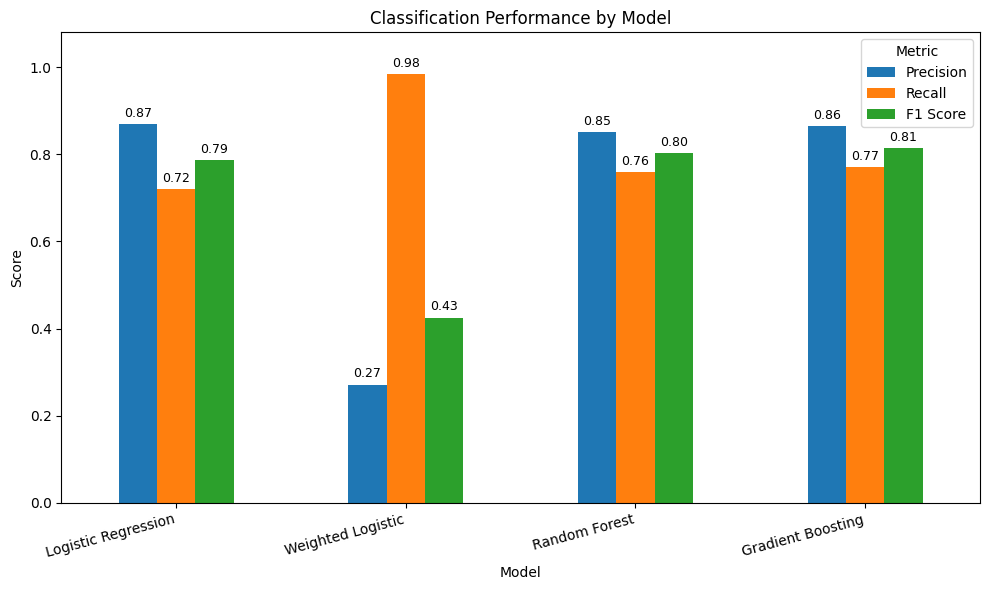

In [59]:
ax = model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Classification Performance by Model")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)

plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric")

# Add values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()


Findings. On this one split, gradient boosting has the best balance of precision and recall. Weighted logistic regression maximizes recall at the cost of a 22-fold increase in false alerts relative to gradient boosting. Because these figures come from one split at one threshold, the expanded validation below checks whether the ranking holds across folds, after tuning, and at better-chosen thresholds.

## Permutation importance and interpretation

Permutation importance estimates how much shuffling each input reduces the fitted model’s F1 score on a reproducible test sample. Importance is not causation, and strongly ranked synthetic identifiers or simulation variables may reflect dataset generation artifacts. The test-set analysis is exploratory and should not be used to tune the model.


In [60]:
# Reproducible sample from test data
X_test_sample = X_test.sample(
    n=20000,
    random_state=42
)

y_test_sample = y_test.loc[X_test_sample.index]

# Calculate permutation importance using F1
perm_importance = permutation_importance(
    gradient_boosting_model,
    X_test_sample,
    y_test_sample,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create results table
feature_importance = pd.DataFrame({
    "Feature": X_test_sample.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


    Feature  Importance       Std
5    amount    0.491335  0.012339
4  category    0.379628  0.019277
3  merchant    0.194590  0.011124
0      step    0.010637  0.008331
2    gender    0.006022  0.003708
1       age    0.002839  0.005673


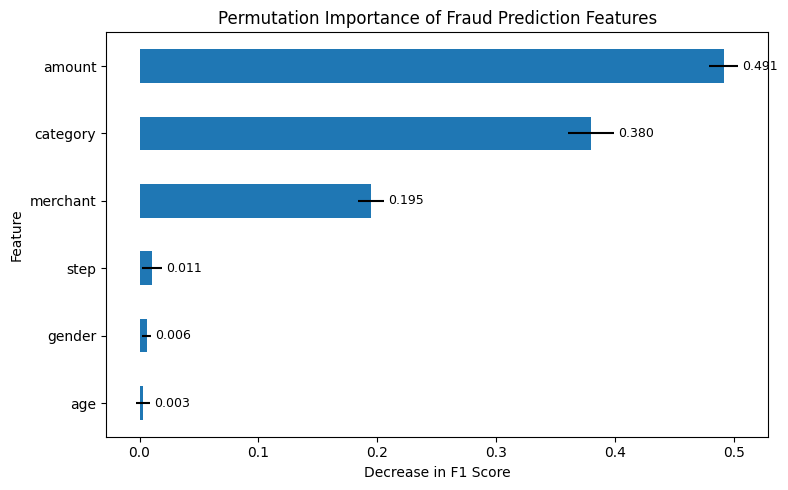

In [61]:
feature_importance_plot = feature_importance.sort_values(
    by="Importance",
    ascending=True
)

ax = feature_importance_plot.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(8, 5),
    legend=False,
    xerr="Std"
)

ax.set_title("Permutation Importance of Fraud Prediction Features")
ax.set_xlabel("Decrease in F1 Score")
ax.set_ylabel("Feature")

for container in ax.containers:
    # Error-bar containers cannot be labelled; label only the bar containers
    if isinstance(container, matplotlib.container.BarContainer):
        ax.bar_label(
            container,
            fmt="%.3f",
            padding=3,
            fontsize=9
        )

plt.tight_layout()
plt.show()

Findings. Shuffling amount reduces F1 by approximately 0.491, followed by category (0.380) and merchant (0.195). These are the strongest predictors in the permutation-importance analysis. Step (0.011), gender (0.006), and age (0.003) have much smaller measured effects. Low importance for age and gender does not guarantee equal model performance across groups. These results describe associations within BankSim, not causal relationships.

# Expanded validation

The initial results used one stratified 80/20 train/test split and a classification threshold of 0.50. To check whether the findings were consistent, I added five-fold cross-validation, hyperparameter tuning, and threshold analysis. Model selection and threshold selection use the training data; the held-out test set is used to evaluate the resulting choices.

## Five-fold stratified cross-validation of all four models

I evaluated each model across five folds of the full training dataset, keeping approximately the same fraud rate in each fold. The mean summarizes performance across folds, and the standard deviation shows how much the results vary.


In [62]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scoring = {"pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}

cv_models = {
    "Logistic Regression": baseline_model,
    "Weighted Logistic": balanced_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
}

cv_rows = []
for name, model in cv_models.items():
    scores = cross_validate(clone(model), X_train, y_train, cv=cv5, scoring=cv_scoring, n_jobs=1)
    row = {"model": name}
    for metric in cv_scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_summary = pd.DataFrame(cv_rows)
print("5-fold stratified CV on the full training set (mean and standard deviation across folds)")
print(cv_summary.round(4).to_string(index=False))

5-fold stratified CV on the full training set (mean and standard deviation across folds)
              model  pr_auc_mean  pr_auc_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std
Logistic Regression       0.8818      0.0127          0.8852         0.0156       0.7234      0.0096   0.7962  0.0117
  Weighted Logistic       0.8745      0.0125          0.2738         0.0030       0.9905      0.0023   0.4290  0.0035
      Random Forest       0.8803      0.0079          0.8562         0.0142       0.7665      0.0064   0.8088  0.0069
  Gradient Boosting       0.8965      0.0087          0.8659         0.0209       0.7679      0.0121   0.8137  0.0086


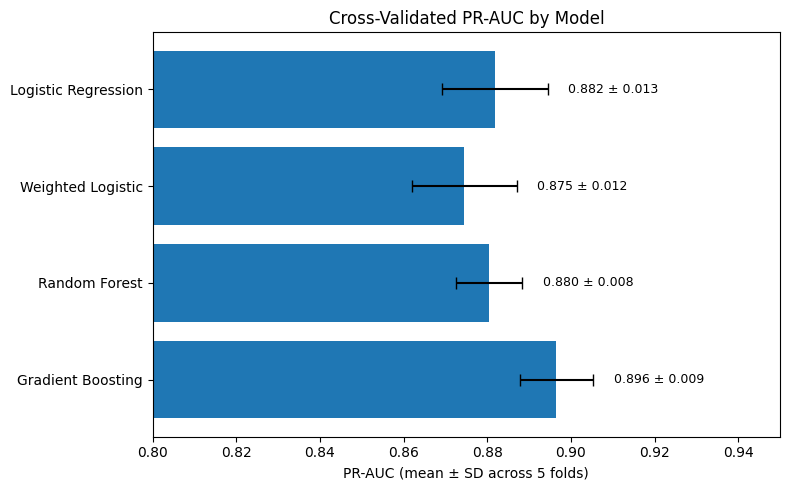

In [63]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cv_summary["model"], cv_summary["pr_auc_mean"], xerr=cv_summary["pr_auc_std"], capsize=4)
for i, (m, s) in enumerate(zip(cv_summary["pr_auc_mean"], cv_summary["pr_auc_std"])):
    ax.text(m + s + 0.005, i, f"{m:.3f} ± {s:.3f}", va="center", fontsize=9)
ax.set_xlim(0.80, 0.95)
ax.set_xlabel("PR-AUC (mean ± SD across 5 folds)")
ax.set_title("Cross-Validated PR-AUC by Model")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Findings. Across five folds, gradient boosting has the highest mean PR-AUC (0.8965 ± 0.0087) and F1 (0.8137 ± 0.0086), ahead of logistic regression (PR-AUC 0.8818 ± 0.0127) and random forest (0.8803 ± 0.0079). The mean PR-AUC advantage is approximately 0.015–0.016. Fold-to-fold variation is relatively small, providing additional support for gradient boosting, although the summary statistics alone do not establish that it wins on every fold. Weighted logistic regression has very high recall (0.9905) but low precision (0.2738).

## Hyperparameter tuning — logistic regression

Why: the regularization strength C controls how strongly coefficients are shrunk; with many one-hot merchant columns, the default may over- or under-fit. Class weighting is included in the grid so the search decides between the weighted and unweighted versions on validation data rather than on the test set. A full grid (4 × 2 = 8 candidates) is searched with 5-fold CV on the full training set, scored by PR-AUC (average precision), which is threshold-independent and suited to rare-event problems.

In [64]:
lr_search = GridSearchCV(
    clone(baseline_model),
    param_grid={"classifier__C": [0.01, 0.1, 1.0, 10.0],
                "classifier__class_weight": [None, "balanced"]},
    scoring="average_precision", cv=cv5, n_jobs=1, refit=True)
lr_search.fit(X_train, y_train)

lr_results = (pd.DataFrame(lr_search.cv_results_)
              [["param_classifier__C", "param_classifier__class_weight", "mean_test_score", "std_test_score", "rank_test_score"]]
              .sort_values("rank_test_score"))
print(lr_results.round(4).to_string(index=False))
print("\nBest parameters:", lr_search.best_params_)
print("Best CV PR-AUC:  ", round(lr_search.best_score_, 4))

tuned_lr_prob = lr_search.best_estimator_.predict_proba(X_test)[:, 1]
print("Held-out test PR-AUC (tuned logistic):", round(average_precision_score(y_test, tuned_lr_prob), 4))

 param_classifier__C param_classifier__class_weight  mean_test_score  std_test_score  rank_test_score
                1.00                           None           0.8818          0.0127                1
               10.00                           None           0.8811          0.0122                2
                0.10                           None           0.8778          0.0126                3
                1.00                       balanced           0.8745          0.0125                4
                0.10                       balanced           0.8739          0.0123                5
               10.00                       balanced           0.8737          0.0122                6
                0.01                       balanced           0.8657          0.0128                7
                0.01                           None           0.8506          0.0136                8

Best parameters: {'classifier__C': 1.0, 'classifier__class_weight': None}
Best CV

Findings. The grid search confirms the default C = 1.0 without class weighting as the best logistic configuration (CV PR-AUC 0.882); C = 10 is effectively tied, while strong regularization (C = 0.01) hurts. Class weighting lowers PR-AUC at every C, so on validation data the search itself rejects the weighted variant. The tuned logistic model's test PR-AUC (0.883) equals the baseline's, indicating the original logistic model was already well specified.

## Hyperparameter tuning — gradient boosting

Why: gradient boosting was the strongest untuned model, so it is the model most worth tuning and the one recommended in the paper. A randomized search samples 20 of 216 combinations of learning rate, number of boosting iterations, tree size (max_leaf_nodes), minimum leaf size, and L2 regularization, each evaluated with 5-fold CV on the full training set (100 fits). Randomized search covers a wide space at a fraction of the cost of a full grid.

In [65]:
gb_param_dist = {
    "classifier__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "classifier__max_iter": [200, 400],
    "classifier__max_leaf_nodes": [15, 31, 63],
    "classifier__min_samples_leaf": [20, 50, 100],
    "classifier__l2_regularization": [0.0, 0.1, 1.0],
}
gb_search = RandomizedSearchCV(
    clone(gradient_boosting_model), gb_param_dist, n_iter=20,
    scoring="average_precision", cv=cv5, random_state=42, n_jobs=1, refit=True)
gb_search.fit(X_train, y_train)

param_cols = ["param_" + p for p in gb_param_dist]
gb_results = (pd.DataFrame(gb_search.cv_results_)
              [param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
              .sort_values("rank_test_score"))
gb_results.columns = [c.replace("param_classifier__", "") for c in gb_results.columns]
print("Top 5 of 20 sampled configurations (5-fold CV PR-AUC):")
print(gb_results.head(5).round(4).to_string(index=False))
print("\nOriginal configuration CV PR-AUC:",
      round(cv_summary.loc[cv_summary.model == "Gradient Boosting", "pr_auc_mean"].item(), 4))
print("Best parameters:", {k.replace("classifier__", ""): v for k, v in gb_search.best_params_.items()})
print("Best CV PR-AUC:  ", round(gb_search.best_score_, 4))

tuned_gb = gb_search.best_estimator_
tuned_gb_prob = tuned_gb.predict_proba(X_test)[:, 1]
tuned_gb_pred = (tuned_gb_prob >= 0.5).astype(int)
print("\nHeld-out test results, tuned gradient boosting at threshold 0.50:")
print("  PR-AUC   ", round(average_precision_score(y_test, tuned_gb_prob), 4))
print("  Precision", round(precision_score(y_test, tuned_gb_pred), 4))
print("  Recall   ", round(recall_score(y_test, tuned_gb_pred), 4))
print("  F1       ", round(f1_score(y_test, tuned_gb_pred), 4))
print("  Confusion matrix:\n", confusion_matrix(y_test, tuned_gb_pred))

Top 5 of 20 sampled configurations (5-fold CV PR-AUC):
 learning_rate  max_iter  max_leaf_nodes  min_samples_leaf  l2_regularization  mean_test_score  std_test_score  rank_test_score
          0.03       400              15                20                0.0           0.9040          0.0087                1
          0.05       400              31                20                0.0           0.9028          0.0076                2
          0.03       400              15                50                1.0           0.9028          0.0091                3
          0.10       400              15                50                1.0           0.9026          0.0086                4
          0.05       400              31               100                1.0           0.9026          0.0084                5

Original configuration CV PR-AUC: 0.8965
Best parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.03, 'l2_regularization': 0.0}
Best 

Findings. The best of 20 sampled configurations (learning rate 0.03, 400 iterations, 15 leaf nodes, minimum leaf size 20, no L2 penalty) uses a slower learning rate and smaller trees. It raises CV PR-AUC from 0.8965 to 0.9040. On the held-out test set, the tuned model achieves PR-AUC 0.8982. At the 0.50 threshold, it detects 1,084 of 1,440 fraud cases with 157 false alerts (precision 0.8735, recall 0.7528, F1 0.8087). Tuning modestly improves cross-validated ranking performance, but the operating threshold still needs to reflect the costs of missed fraud and false alerts.

## Decision-threshold selection from out-of-fold predictions

Why: the default 0.50 cut-off is arbitrary for a rare event; the operating threshold should reflect the trade-off between missed fraud and false alerts. To avoid choosing a threshold on the test set, cross_val_predict produces an out-of-fold fraud probability for every training transaction (each predicted by a model that never saw it). Thresholds are then chosen on those predictions under two rules:

- F1-optimal: the threshold that maximizes F1 (equal weight on precision and recall).
- Recall target: the highest threshold that still detects at least 85% of fraud, representing an institution that prioritizes catching fraud and has review capacity for more alerts.

Each chosen threshold is then applied once to the untouched test set.

In [66]:
oof_prob = cross_val_predict(clone(tuned_gb), X_train, y_train, cv=cv5, method="predict_proba", n_jobs=1)[:, 1]

grid = np.round(np.arange(0.01, 1.00, 0.01), 2)
oof_rows = []
for t in grid:
    p = (oof_prob >= t).astype(int)
    oof_rows.append({"threshold": t,
                     "precision": precision_score(y_train, p, zero_division=0),
                     "recall": recall_score(y_train, p, zero_division=0),
                     "f1": f1_score(y_train, p, zero_division=0)})
oof_table = pd.DataFrame(oof_rows)

f1_threshold = oof_table.loc[oof_table["f1"].idxmax(), "threshold"]
recall_threshold = oof_table.loc[oof_table["recall"] >= 0.85, "threshold"].max()
print("Out-of-fold training PR-AUC:", round(average_precision_score(y_train, oof_prob), 4))
print("F1-optimal threshold (OOF):        ", f1_threshold)
print("Recall >= 0.85 threshold (OOF):    ", recall_threshold)

def test_metrics(prob, t, label):
    p = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0, 1]).ravel()
    return {"operating point": label, "threshold": t,
            "precision": precision_score(y_test, p, zero_division=0),
            "recall": recall_score(y_test, p, zero_division=0),
            "f1": f1_score(y_test, p, zero_division=0),
            "fraud_detected": int(tp), "fraud_missed": int(fn), "false_alerts": int(fp)}

operating_points = pd.DataFrame([
    test_metrics(tuned_gb_prob, 0.50, "Default"),
    test_metrics(tuned_gb_prob, f1_threshold, "F1-optimal (OOF)"),
    test_metrics(tuned_gb_prob, recall_threshold, "Recall >= 0.85 (OOF)"),
])
print("\nTuned gradient boosting on the untouched test set:")
print(operating_points.round(4).to_string(index=False))

Out-of-fold training PR-AUC: 0.9037
F1-optimal threshold (OOF):         0.36
Recall >= 0.85 threshold (OOF):     0.22

Tuned gradient boosting on the untouched test set:
     operating point  threshold  precision  recall     f1  fraud_detected  fraud_missed  false_alerts
             Default       0.50     0.8735  0.7528 0.8087            1084           356           157
    F1-optimal (OOF)       0.36     0.8358  0.7951 0.8149            1145           295           225
Recall >= 0.85 (OOF)       0.22     0.7683  0.8472 0.8058            1220           220           368


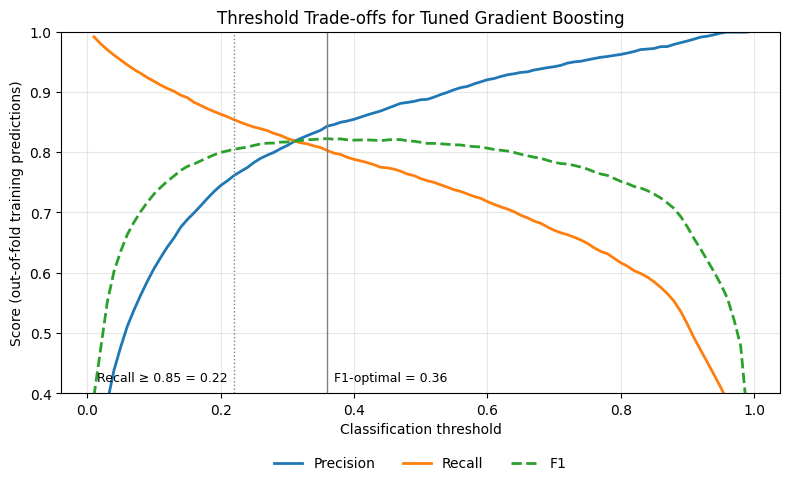

In [67]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(oof_table["threshold"], oof_table["precision"], label="Precision", linewidth=2)
ax.plot(oof_table["threshold"], oof_table["recall"], label="Recall", linewidth=2)
ax.plot(oof_table["threshold"], oof_table["f1"], label="F1", linewidth=2, linestyle="--")
ax.axvline(f1_threshold, color="gray", linewidth=1)
ax.text(f1_threshold + 0.01, 0.42, f"F1-optimal = {f1_threshold:.2f}", fontsize=9)
ax.axvline(recall_threshold, color="gray", linewidth=1, linestyle=":")
ax.text(recall_threshold - 0.01, 0.42, f"Recall ≥ 0.85 = {recall_threshold:.2f}", fontsize=9, ha="right")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score (out-of-fold training predictions)")
ax.set_title("Threshold Trade-offs for Tuned Gradient Boosting")
ax.set_ylim(0.4, 1.0)
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

Findings. The highest F1 score on the out-of-fold training predictions occurred at a threshold of 0.36. The training-data threshold selected to target at least 0.85 recall was 0.22. On the held-out test data, the 0.36 threshold detected 1,145 of 1,440 fraud cases and produced 225 false alerts (precision 0.836, recall 0.795, F1 0.815). Lowering the threshold to 0.22 detected 75 additional fraud cases but increased false alerts to 368; test recall was 0.847, slightly below the training target. These results show why the threshold should reflect the relative costs of missed fraud and false alerts. I use 0.36 for the final subgroup analysis.

### Illustrative test-set threshold sweep (original gradient boosting model)

For transparency, the table below repeats the descriptive sweep from the earlier draft on the original model's test predictions. It shows the shape of the trade-off but is not used to choose a threshold; the out-of-fold selection above is the validated procedure.

In [68]:
threshold_rows=[]
for cutoff in [0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.80,0.90]:
    pred=(gb_prob>=cutoff).astype(int)
    tn_t,fp_t,fn_t,tp_t=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    threshold_rows.append({'threshold':cutoff,'precision':precision_score(y_test,pred,zero_division=0),
       'recall':recall_score(y_test,pred,zero_division=0),
       'f1':f1_score(y_test,pred,zero_division=0),
       'fraud_detected':int(tp_t),'fraud_missed':int(fn_t),'false_alerts':int(fp_t)})
threshold_table=pd.DataFrame(threshold_rows)
print(threshold_table.round(4).to_string(index=False))


 threshold  precision  recall     f1  fraud_detected  fraud_missed  false_alerts
       0.1     0.6370  0.8993 0.7458            1295           145           738
       0.2     0.7461  0.8569 0.7977            1234           206           420
       0.3     0.8098  0.8160 0.8129            1175           265           276
       0.4     0.8378  0.7965 0.8167            1147           293           222
       0.5     0.8644  0.7701 0.8145            1109           331           174
       0.6     0.8843  0.7326 0.8014            1055           385           138
       0.7     0.9070  0.6910 0.7844             995           445           102
       0.8     0.9394  0.6354 0.7581             915           525            59
       0.9     0.9659  0.5701 0.7170             821           619            29


Findings. The test-set sweep shows the same trade-off. Moving from a threshold of 0.50 to 0.20 increases detected fraud cases from 1,109 to 1,234 (125 additional detections) and false alerts from 174 to 420 (246 additional alerts). At a threshold of 0.80, the model produces 59 false alerts but misses 525 fraud cases. These test-set comparisons illustrate the trade-off; the final threshold of 0.36 was selected using out-of-fold training predictions, not this test-set sweep.

# Sensitivity tests: simulation-specific features

## Feature ablation: merchant and step

Because BankSim is simulated, merchant identifiers and the transaction step could reflect patterns specific to the dataset. For example, every step contains exactly 40 fraud cases. I refitted the original gradient-boosting model after excluding merchant, step, and both features to see how much each contributed to its performance.


In [69]:
ablation_rows=[]
for omit in [[],['merchant'],['step'],['merchant','step']]:
    cols=[c for c in X_train.columns if c not in omit]
    numeric=[c for c in ['step','amount'] if c in cols]
    categorical=[c for c in ['age','gender','merchant','category'] if c in cols]
    transform=[]
    if numeric: transform.append(('num','passthrough',numeric))
    if categorical: transform.append(('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),categorical))
    pipe=Pipeline([('preprocessor',ColumnTransformer(transform)),
        ('classifier',HistGradientBoostingClassifier(max_iter=200,learning_rate=0.1,random_state=42))])
    pipe.fit(X_train[cols],y_train)
    probs=pipe.predict_proba(X_test[cols])[:,1]
    preds=(probs>=0.5).astype(int)
    ablation_rows.append({'excluded':', '.join(omit) or 'none',
       'pr_auc':average_precision_score(y_test,probs),
       'precision':precision_score(y_test,preds,zero_division=0),
       'recall':recall_score(y_test,preds,zero_division=0),
       'false_alerts':int(((preds==1)&(y_test.to_numpy()==0)).sum())})
print(pd.DataFrame(ablation_rows).round(4).to_string(index=False))

      excluded  pr_auc  precision  recall  false_alerts
          none  0.8960     0.8644  0.7701           174
      merchant  0.8050     0.8448  0.6500           172
          step  0.8952     0.8699  0.7757           167
merchant, step  0.8053     0.8603  0.6417           150


Findings. Removing merchant lowers PR-AUC from 0.8960 to 0.8050 and recall from 0.7701 to 0.6500. False alerts change slightly, from 174 to 172. Removing step has little effect (PR-AUC 0.8952, recall 0.7757, and 167 false alerts). Removing both merchant and step gives PR-AUC 0.8053 and recall 0.6417. These results suggest substantial reliance on merchant identity, which may reflect simulation-specific patterns, while step contributes relatively little.

## Time-based validation: training on earlier steps and testing on later steps

I also tested the model using steps 0–143 for training and steps 144–179 for testing. This checks performance on later transactions rather than using a random split across the entire simulation. I used the tuned gradient-boosting settings and compared versions with and without the step feature. Removing step does not remove the fixed pattern of 40 fraud cases per step, so this experiment cannot rule out every effect of the simulation design.


In [70]:
best_gb_params = {k.replace("classifier__", ""): v for k, v in gb_search.best_params_.items()}

def build_gb(cols, params):
    numeric = [c for c in ["step", "amount"] if c in cols]
    categorical = [c for c in ["age", "gender", "merchant", "category"] if c in cols]
    transformers = []
    if numeric:
        transformers.append(("num", "passthrough", numeric))
    if categorical:
        transformers.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical))
    return Pipeline([("preprocessor", ColumnTransformer(transformers)),
                     ("classifier", HistGradientBoostingClassifier(random_state=42, **params))])

time_cutoff = 144
time_train = X["step"] < time_cutoff
Xt_train, Xt_test = X[time_train], X[~time_train]
yt_train, yt_test = y[time_train], y[~time_train]
print(f"Time split - train: steps 0-{time_cutoff-1}, {len(Xt_train):,} rows, {yt_train.sum():,} fraud")
print(f"             test:  steps {time_cutoff}-{X['step'].max()}, {len(Xt_test):,} rows, {yt_test.sum():,} fraud\n")

time_rows = []
for omit in [[], ["step"], ["merchant"], ["merchant", "step"]]:
    cols = [c for c in X.columns if c not in omit]
    model = build_gb(cols, best_gb_params).fit(Xt_train[cols], yt_train)
    prob = model.predict_proba(Xt_test[cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    time_rows.append({"excluded": ", ".join(omit) or "none",
                      "pr_auc": average_precision_score(yt_test, prob),
                      "precision": precision_score(yt_test, pred, zero_division=0),
                      "recall": recall_score(yt_test, pred, zero_division=0),
                      "false_alerts": int(((pred == 1) & (yt_test.to_numpy() == 0)).sum())})
time_table = pd.DataFrame(time_rows)
print("Tuned gradient boosting, time-based split, threshold 0.50:")
print(time_table.round(4).to_string(index=False))

Time split - train: steps 0-143, 461,412 rows, 5,760 fraud
             test:  steps 144-179, 133,231 rows, 1,440 fraud

Tuned gradient boosting, time-based split, threshold 0.50:
      excluded  pr_auc  precision  recall  false_alerts
          none  0.9209     0.9058  0.7542           113
          step  0.9227     0.9392  0.7299            68
      merchant  0.8079     0.8867  0.6250           115
merchant, step  0.8066     0.8844  0.6215           117


Findings. Training on steps 0–143 and testing on steps 144–179 produces PR-AUC 0.9209, recall 0.7542, and 113 false alerts with all features. Removing step gives PR-AUC 0.9227, recall 0.7299, and 68 false alerts. Removing merchant reduces PR-AUC to 0.8079. These results suggest that the model can identify fraud in later simulation steps without relying heavily on the step feature. However, the fixed 40-fraud-per-step pattern and other simulation artifacts remain limitations. The random and time-based splits are not directly comparable because their fraud rates differ.

### Encoding sensitivity
Ordinal encoding imposes artificial ordering on merchant and category labels. Refit the gradient boosting model with one-hot encoding to see whether the results depend on this representation. One-hot encoding increases the feature count and can affect computation and model behavior.

In [71]:
onehot_gb=Pipeline([('preprocessor',ColumnTransformer([
    ('num','passthrough',['step','amount']),
    ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['age','gender','merchant','category'])])),
    ('classifier',HistGradientBoostingClassifier(max_iter=200,learning_rate=0.1,random_state=42))])
onehot_gb.fit(X_train,y_train)
onehot_prob=onehot_gb.predict_proba(X_test)[:,1]
onehot_pred=(onehot_prob>=0.5).astype(int)
print({'encoding':'one-hot','pr_auc':round(average_precision_score(y_test,onehot_prob),4),
       'precision':round(precision_score(y_test,onehot_pred,zero_division=0),4),
       'recall':round(recall_score(y_test,onehot_pred,zero_division=0),4)})

{'encoding': 'one-hot', 'pr_auc': 0.8921, 'precision': 0.8733, 'recall': 0.7562}


Findings. One-hot encoding produces PR-AUC 0.8921, precision 0.8733, and recall 0.7562. The ordinal-encoded model produces PR-AUC 0.8960, precision 0.8644, and recall 0.7701. Performance is broadly similar under both encodings, suggesting that the artificial ordering introduced by ordinal encoding does not materially drive the results. Merchant identity remains an important predictor under both approaches.

# Subgroup performance: coded age and gender

I evaluated the final tuned gradient-boosting model at threshold 0.36 separately for the coded age and gender groups. For each group, the analysis reports fraud recall and false-positive rate, along with Wilson 95% confidence intervals. I also used chi-square tests to examine whether recall differed across groups.

Groups with fewer than 30 fraud cases in the test set (age 0 and U; gender E and U) are displayed for completeness but excluded from the significance tests because their estimates are based on too few cases.


In [72]:
def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))

final_threshold = f1_threshold
final_pred = (tuned_gb_prob >= final_threshold).astype(int)
truth = y_test.to_numpy()

def subgroup_metrics(feature, preds):
    rows = []
    groups = X_test[feature].astype(str).str.strip("'")
    for group in sorted(groups.unique()):
        mask = (groups == group).to_numpy()
        yt, yp = truth[mask], preds[mask]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        r_lo, r_hi = wilson_ci(tp, tp + fn)
        f_lo, f_hi = wilson_ci(fp, fp + tn)
        rows.append({"attribute": feature, "group": group, "n": int(mask.sum()),
                     "fraud_n": int(tp + fn),
                     "precision": tp / (tp + fp) if tp + fp else np.nan,
                     "recall": tp / (tp + fn) if tp + fn else np.nan,
                     "recall_95ci": f"[{r_lo:.3f}, {r_hi:.3f}]" if tp + fn else "n/a",
                     "fpr": fp / (fp + tn) if fp + tn else np.nan,
                     "fpr_95ci": f"[{f_lo:.4f}, {f_hi:.4f}]",
                     "false_alerts": int(fp), "tp": int(tp), "fn": int(fn)})
    return pd.DataFrame(rows)

fairness_table = pd.concat([subgroup_metrics("age", final_pred), subgroup_metrics("gender", final_pred)],
                           ignore_index=True)
print(f"Final model: tuned gradient boosting, threshold {final_threshold:.2f}")
print(fairness_table.drop(columns=["tp", "fn"]).round(4).to_string(index=False))

print("\nChi-square tests of equal recall (groups with >= 30 test fraud cases):")
for attr in ["age", "gender"]:
    sub = fairness_table[(fairness_table.attribute == attr) & (fairness_table.fraud_n >= 30)]
    chi2, p, dof, _ = stats.chi2_contingency(sub[["tp", "fn"]].to_numpy())
    print(f"  {attr:6s} groups {list(sub.group)}: chi2 = {chi2:.2f}, df = {dof}, p = {p:.3f}")
    fp_tab = np.column_stack([sub.false_alerts, (sub.n - sub.fraud_n) - sub.false_alerts])
    chi2f, pf, doff, _ = stats.chi2_contingency(fp_tab)
    print(f"  {attr:6s} false-positive rate:            chi2 = {chi2f:.2f}, df = {doff}, p = {pf:.3f}")

Final model: tuned gradient boosting, threshold 0.36
attribute group     n  fraud_n  precision  recall    recall_95ci    fpr         fpr_95ci  false_alerts
      age     0   483       10     0.7692  1.0000 [0.722, 1.000] 0.0063 [0.0022, 0.0185]             3
      age     1 11526      131     0.7863  0.7863 [0.708, 0.848] 0.0025 [0.0017, 0.0035]            28
      age     2 37581      475     0.8190  0.8000 [0.762, 0.834] 0.0023 [0.0018, 0.0028]            84
      age     3 29434      348     0.8394  0.7960 [0.751, 0.835] 0.0018 [0.0014, 0.0024]            53
      age     4 21827      275     0.8649  0.8145 [0.764, 0.856] 0.0016 [0.0012, 0.0023]            35
      age     5 12438      155     0.8881  0.7677 [0.695, 0.827] 0.0012 [0.0007, 0.0020]            15
      age     6  5392       45     0.8158  0.6889 [0.543, 0.805] 0.0013 [0.0006, 0.0027]             7
      age     U   248        1     1.0000  1.0000 [0.207, 1.000] 0.0000 [0.0000, 0.0153]             0
   gender     E   24

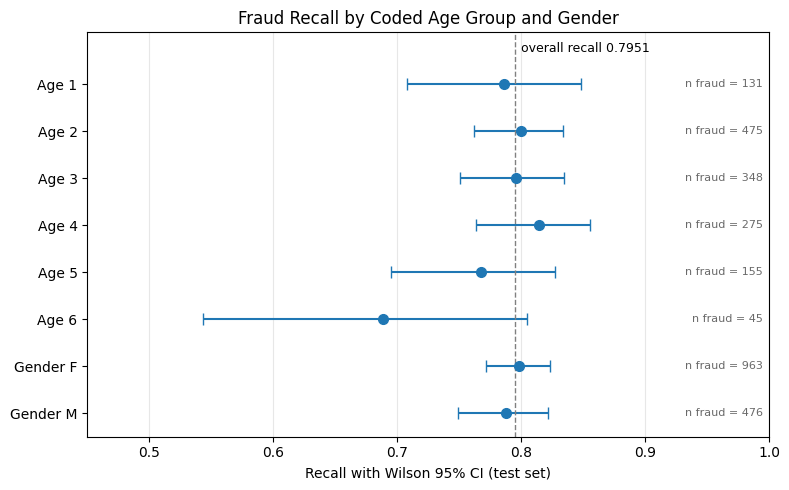

In [73]:
plot_df = fairness_table[fairness_table.fraud_n >= 30].copy()
plot_df["label"] = plot_df["attribute"].str.capitalize() + " " + plot_df["group"]
lo = plot_df["recall_95ci"].str.strip("[]").str.split(", ").str[0].astype(float)
hi = plot_df["recall_95ci"].str.strip("[]").str.split(", ").str[1].astype(float)

fig, ax = plt.subplots(figsize=(8, 5))
ypos = np.arange(len(plot_df))
ax.errorbar(plot_df["recall"], ypos, xerr=[plot_df["recall"] - lo, hi - plot_df["recall"]],
            fmt="o", markersize=7, capsize=4)
for yi, (r, n) in enumerate(zip(plot_df["recall"], plot_df["fraud_n"])):
    ax.text(0.995, yi, f"n fraud = {n}", va="center", ha="right", fontsize=8, color="dimgray")
overall_recall = recall_score(y_test, final_pred)
ax.axvline(overall_recall, color="gray", linestyle="--", linewidth=1)
ax.text(overall_recall + 0.005, -0.75, f"overall recall {overall_recall:.4f}", fontsize=9, va="center")
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df["label"])
ax.set_ylim(len(plot_df) - 0.5, -1.1)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("Recall with Wilson 95% CI (test set)")
ax.set_title("Fraud Recall by Coded Age Group and Gender")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Findings. At threshold 0.36, recall was similar for the two main gender categories: 0.799 for F and 0.788 for M (p = 0.685). False-positive rates were also similar (0.21% and 0.17%, respectively; p = 0.231). Recall for age groups 1–5 ranged from 0.768 to 0.815. Age group 6, identified in the dataset documentation as the oldest group (over 65), had lower recall at 0.689 (95% CI [0.543, 0.805]), compared with overall recall of 0.795. However, age group 6 contained only 45 fraudulent transactions in the test set, and the overall age-group comparison was not statistically significant (p = 0.473). This result warrants further investigation with more data rather than a conclusion that the model is unfair. The table above provides the subgroup confidence intervals and other performance measures.

# Ethical risk register: likelihood and impact ratings

Each risk receives a specific rating on a three-point scale (1 = Low, 2 = Medium, 3 = High) for likelihood and impact, and a risk score = likelihood × impact (1–9). Ratings are analyst judgments for a hypothetical deployment at a financial institution, informed by the evidence column from this notebook; they are not probabilities measured from BankSim. Risks are sorted by score.

In [74]:
rating = {1: "Low", 2: "Medium", 3: "High"}
risks = [
    ("Simulation-specific merchant patterns do not transfer", 3, 3,
     "Removing merchant cuts PR-AUC by 0.091 (random split) and 0.113 (time split)",
     "Validate on representative institutional data; repeat merchant ablation before deployment"),
    ("Missed fraud (false negatives)", 3, 3,
     "Final model misses 295 of 1,440 test fraud cases (20.5%)",
     "Cost-based threshold selection; layered controls; monitor recall on confirmed cases"),
    ("Unequal performance across age groups", 2, 3,
     "Age 6 recall 0.689 (CI 0.543-0.805) vs. 0.795 overall; omnibus p = 0.473",
     "Monitor subgroup recall/FPR with CIs; larger-sample audit of older customers"),
    ("Customer disruption from false alerts", 3, 2,
     "225 false alerts per 117,489 legitimate test transactions; 368 at threshold 0.22",
     "Size threshold to review capacity; low-friction verification; track complaint rates"),
    ("Overreliance on automated scores", 2, 3,
     "Precision 0.836 means about 1 in 6 alerts is a legitimate customer",
     "Human review of consequential actions; documented appeal and override process"),
    ("Performance drift as fraud tactics change", 2, 3,
     "Stable across BankSim steps (time-split PR-AUC 0.921), but real fraud adapts",
     "Drift monitoring, scheduled retraining, champion-challenger evaluation"),
    ("Privacy breach or unauthorized data access", 1, 3,
     "Not testable on synthetic data; real transaction data is highly sensitive",
     "Least-privilege access, minimization, retention limits, audit logging, privacy review"),
]
risk_register = pd.DataFrame(risks, columns=["risk", "likelihood", "impact", "evidence", "mitigation"])
risk_register["score"] = risk_register["likelihood"] * risk_register["impact"]
risk_register["likelihood"] = risk_register["likelihood"].map(lambda v: f"{rating[v]} ({v})")
risk_register["impact"] = risk_register["impact"].map(lambda v: f"{rating[v]} ({v})")
risk_register = risk_register.sort_values("score", ascending=False, kind="stable")
with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    print(risk_register[["risk", "likelihood", "impact", "score", "evidence"]].to_string(index=False))
    print()
    print(risk_register[["risk", "mitigation"]].to_string(index=False))

                                                 risk likelihood     impact  score                                                                         evidence
Simulation-specific merchant patterns do not transfer   High (3)   High (3)      9     Removing merchant cuts PR-AUC by 0.091 (random split) and 0.113 (time split)
                       Missed fraud (false negatives)   High (3)   High (3)      9                         Final model misses 295 of 1,440 test fraud cases (20.5%)
                Unequal performance across age groups Medium (2)   High (3)      6         Age 6 recall 0.689 (CI 0.543-0.805) vs. 0.795 overall; omnibus p = 0.473
                Customer disruption from false alerts   High (3) Medium (2)      6 225 false alerts per 117,489 legitimate test transactions; 368 at threshold 0.22
                     Overreliance on automated scores Medium (2)   High (3)      6               Precision 0.836 means about 1 in 6 alerts is a legitimate customer
            Perf

Findings. The two highest-scoring risks (score 9) are merchant-dependent simulation patterns and missed fraud. Both are supported by the analysis: removing merchant reduces PR-AUC by approximately 0.09–0.11, and the final model misses 295 of 1,440 test fraud cases (20.5%). Subgroup disparity is rated Medium likelihood because the oldest age group has lower observed recall, although its confidence interval overlaps the overall recall and the age-group comparison is not statistically significant.

# Summary of findings

1. Accuracy is misleading at a 1.21% fraud rate. Weighted logistic regression reaches very high recall but generates many false alerts, while overall accuracy can still appear high.
2. Gradient boosting has the strongest overall performance among the models tested. It leads in five-fold CV (PR-AUC 0.8965 ± 0.0087, compared with 0.8803–0.8818 for unweighted logistic regression and random forest) and performs well on the held-out test set.
3. Tuning produces modest improvements. Gradient-boosting CV PR-AUC increases from 0.8965 to 0.9040, while the default logistic regression settings perform best among the configurations tested.
4. Threshold choice matters as much as model choice. Thresholds selected on out-of-fold training data give 0.36 (F1-optimal: 1,145 detected and 225 false alerts on test) or 0.22 (targeting 0.85 recall: 1,220 detected and 368 false alerts). The appropriate threshold depends on investigation capacity and the cost of missed fraud.
5. Merchant identity substantially affects model performance, while removing step has little effect in the tests performed. Removing merchant reduces PR-AUC by approximately 0.09–0.11 across the random and time-based splits. Encoding choice has relatively little effect.
6. Subgroup performance is broadly similar, with one concern. Recall is similar across the main gender groups and age groups 1–5. Age group 6 has lower recall (0.689, 95% CI [0.543, 0.805]), although the overall age-group comparison is not statistically significant (p = 0.473). This group should be evaluated further using a larger sample.
7. All results are based on synthetic BankSim data. Deployment would require validation on representative institutional data, cost-based threshold selection, subgroup monitoring, and human review of consequential alerts.